In [1]:
import torch
import torch.nn as nn
from torchvision import transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import clear_output
import random
from torch.utils.data import Dataset, DataLoader
import os
from glob import glob
from PIL import Image
import json
from utils import moving_average

In [2]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

# Choisir le GPU et vérifier
torch.cuda.set_device(0)
print(torch.cuda.current_device())  # doit afficher le numéro choisi dans torch.cuda.set_device()
print(torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
0
Tesla V100S-PCIE-32GB


In [3]:
batch_size = 512
n_epochs = 10
n_classes = 5
crop_size = 32

In [4]:
class ImageDataset(Dataset):

    def __init__(self, split, transform=None):
        self.transform = transform

        # get the dictionnary with the crop's infos
        with open(f'data/dataset_crops/{split}_{crop_size}x{crop_size}_data.json', 'r', encoding='utf-8') as f:
            dico = json.load(f)

        # get all image paths, attributs and classes
        self.data = []

        for path in glob(os.path.join(f"data/dataset_crops/{split}", "**", "*.png"), recursive=True):
            filename = os.path.basename(path)      # "crop_i.png"
            crop_name = os.path.splitext(filename)[0]   # "crop_i"

            attributs = dico[crop_name]["attributs"]
            damage = dico[crop_name]["niveau de brûlé"]

            self.data.append((path, attributs, damage))


    def __len__(self):
        return len(self.data)


    def __getitem__(self, idx):
        img_path, attribut, label = self.data[idx]

        img = Image.open(img_path).convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        attribut = torch.tensor(attribut, dtype=torch.float32)
        label = torch.tensor(label, dtype=torch.int64)

        return img, attribut, label


# transformations ajoutées pour faire de la data augmentation autrement il y a de l'overfitting

def random_90_rotation(img):
    angles = [0, 90, 180, 270]
    return transforms.functional.rotate(img, angle=random.choice(angles))

transform = transforms.Compose([
    # transforms.RandomHorizontalFlip(p=0.5),
    # transforms.RandomVerticalFlip(p=0.5),
    # transforms.Lambda(random_90_rotation),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(split="train", transform=transform)
val_dataset = ImageDataset(split="val", transform=transform)

In [5]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=8)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=8)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)

In [6]:
from torchvision.models import resnet18

resnet = resnet18(weights=None)

# remplacer la dernière couche pour avoir le bon nombre de classe et pas les 1000 de ImageNet
in_features = resnet.fc.in_features
resnet.fc = nn.Linear(in_features, n_classes)


resnet = resnet.to(device)

# load the resnet parameters
checkpoint = torch.load("weights/resnet_sur_crops_sat_32x32_checkpoint10.pth", map_location="cpu")
resnet.load_state_dict(checkpoint["model_state_dict"])

resnet.eval()

resnet_minus_last_layer = nn.Sequential(*list(resnet.children())[:-1])


total_params = sum(p.numel() for p in resnet.parameters())
print(f"Total parameters in the resnet: {total_params/1e6:.6f} million")

Total parameters in the resnet: 11.179077 million


In [7]:
import torch.nn.functional as F

class LinearSAE(nn.Module):

    def __init__(self, d_in, k, λ):
        super().__init__()
        self.enc = nn.Linear(d_in, k, bias=False)
        self.dec = nn.Linear(k, d_in, bias=False)
        self.λ   = λ

        nn.init.kaiming_normal_(self.enc.weight, nonlinearity='relu')
        nn.init.normal_(self.dec.weight, 0, 0.01)

    def forward(self, x):
        z = F.relu(self.enc(x))
        x_hat = self.dec(z)
        return x_hat, z

    def loss(self, x_hat, x, z):
        rec   = F.mse_loss(x_hat, x)
        spars = z.abs().mean()
        return rec + self.λ * spars, rec.item(), spars.item()

# SAE 
sae = LinearSAE(d_in=512, k=2048, λ=1e-3).to(device)

# load weights
checkpoint = torch.load(f"weights/sae_{crop_size}x{crop_size}_checkpoint2.pth", map_location="cpu")
sae.load_state_dict(checkpoint["model_state_dict"])

sae.eval()

total_params = sum(p.numel() for p in sae.parameters())
print(f"Total parameters in the sae: {total_params/1e6:.6f} million")

Total parameters in the sae: 2.097152 million


In [8]:
fully_connected = nn.Sequential(
    nn.Linear(2048, 60),
    nn.Sigmoid()
).to(device)

checkpoint = torch.load(f"weights/fully_connected_{crop_size}x{crop_size}_checkpoint2.pth", map_location="cpu")
fully_connected.load_state_dict(checkpoint["model_state_dict"])

fully_connected.eval()

total_params = sum(p.numel() for p in fully_connected.parameters())
print(f"Total parameters in the fully connected layer: {total_params/1e6:.6f} million")

Total parameters in the fully connected layer: 0.122940 million


100%|██████████| 194/194 [00:14<00:00, 13.48it/s]


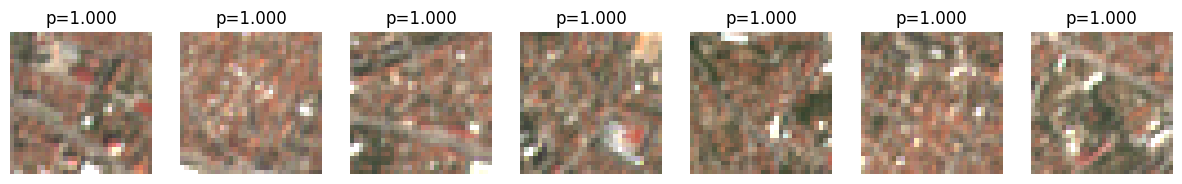

In [9]:
# CODE POUR TROUVER LES IMAGES QUI CORRESPONDENT À L'ACTIVATION D'UN ATTRIBUT

attribut_index = 19    # zones très construites

top_k = 7
top_probs = []
top_imgs = []

for i, (imgs, attributs, classes) in tqdm(enumerate(val_loader), total=len(val_loader)):
    
    imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)

    with torch.no_grad():
        # get the activation of the layer before the output
        x = resnet_minus_last_layer(imgs)
        x = x.view(x.shape[0], -1)  # flatten the output

        # put it in the sparse autoencoder
        x_hat, z = sae(x)

        # use z to predict the attributs
        attributs_pred = fully_connected(z)

        # find the probability of the attribut we are looking for
        probs = attributs_pred[:, attribut_index]

        # mettre à jour le top-k
        for j, p in enumerate(probs):
            if len(top_probs) < top_k:
                top_probs.append(p.item())
                top_imgs.append(imgs[j].detach().cpu())
            else:
                min_idx = int(torch.argmin(torch.tensor(top_probs)))
                if p.item() > top_probs[min_idx]:
                    top_probs[min_idx] = p.item()
                    top_imgs[min_idx] = imgs[j].detach().cpu()


# Trier les résultats du plus grand au plus petit
sorted_indices = sorted(range(len(top_probs)), key=lambda k: top_probs[k], reverse=True)
top_probs = [top_probs[k] for k in sorted_indices]
top_imgs  = [top_imgs[k] for k in sorted_indices]


# Affichage des images
fig, axes = plt.subplots(1, top_k, figsize=(15,5))
for idx, ax in enumerate(axes):
    img = top_imgs[idx]
    img = img.permute(1, 2, 0)  # (C,H,W) -> (H,W,C)
    ax.imshow((img+1)/2)
    ax.set_title(f"p={top_probs[idx]:.3f}")
    ax.axis("off")

plt.show()

100%|██████████| 194/194 [00:09<00:00, 20.27it/s]


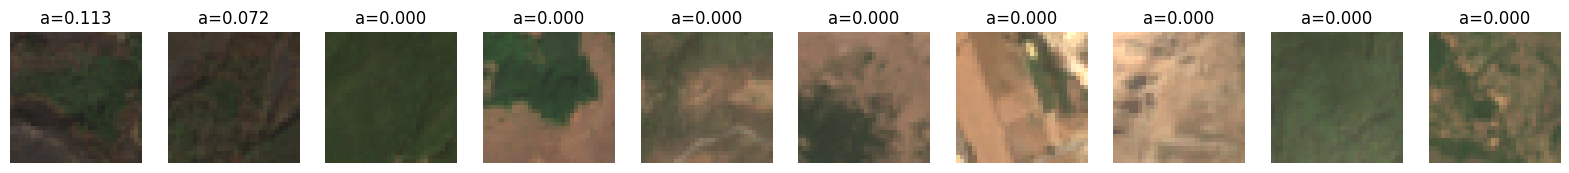

100%|██████████| 194/194 [00:09<00:00, 20.44it/s]


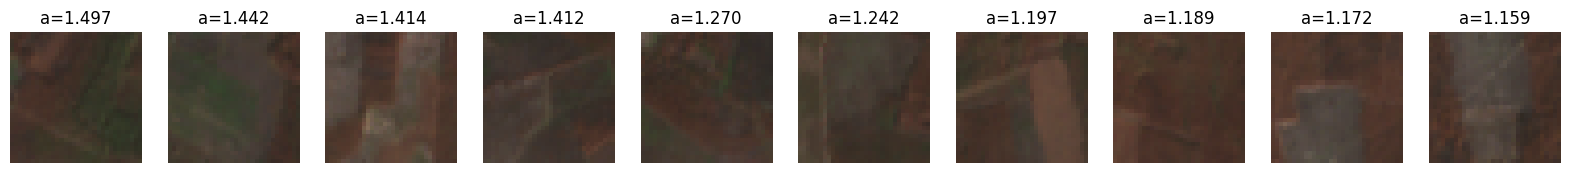

100%|██████████| 194/194 [00:11<00:00, 16.71it/s]


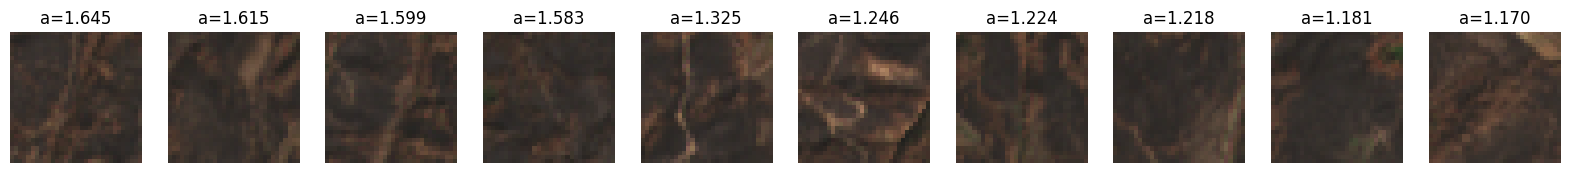

100%|██████████| 194/194 [00:15<00:00, 12.16it/s]


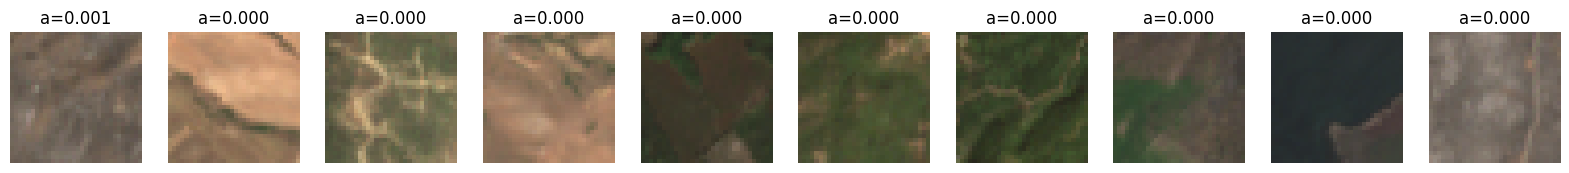

100%|██████████| 194/194 [00:11<00:00, 16.83it/s]


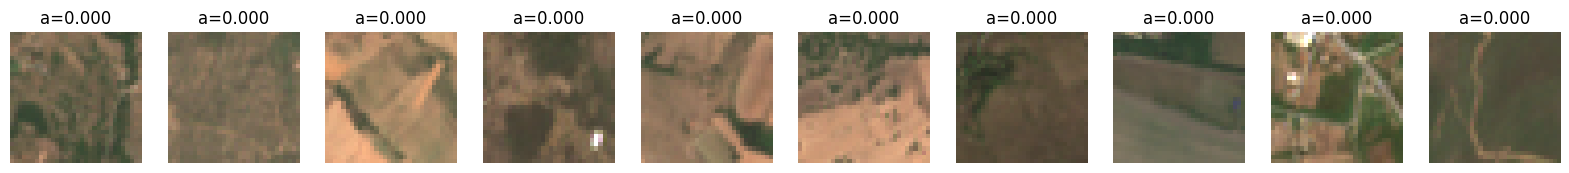

In [12]:
# CODE POUR TROUVER LES IMAGES QUI CORRESPONDENT À L'ACTIVATION D'UN NEURONE

def images_trigger_neurone(neuron_index):

    top_k = 10
    top_activations = []
    top_imgs = []

    for i, (imgs, attributs, classes) in tqdm(enumerate(val_loader), total=len(val_loader)):
        
        imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)

        with torch.no_grad():
            # get the activation of the layer before the output
            x = resnet_minus_last_layer(imgs)
            x = x.view(x.shape[0], -1)  # flatten the output

            # put it in the sparse autoencoder
            x_hat, z = sae(x)

            # find the probability of the attribut we are looking for
            activations = z[:, neuron_index]

            # mettre à jour le top-k
            for j, p in enumerate(activations):
                if len(top_activations) < top_k:
                    top_activations.append(p.item())
                    top_imgs.append(imgs[j].detach().cpu())
                else:
                    min_idx = int(torch.argmin(torch.tensor(top_activations)))
                    if p.item() > top_activations[min_idx]:
                        top_activations[min_idx] = p.item()
                        top_imgs[min_idx] = imgs[j].detach().cpu()


    # Trier les résultats du plus grand au plus petit
    sorted_indices = sorted(range(len(top_activations)), key=lambda k: top_activations[k], reverse=True)
    top_activations = [top_activations[k] for k in sorted_indices]
    top_imgs  = [top_imgs[k] for k in sorted_indices]


    # Affichage des images
    fig, axes = plt.subplots(1, top_k, figsize=(20,7))
    for idx, ax in enumerate(axes):
        img = top_imgs[idx]
        img = img.permute(1, 2, 0)  # (C,H,W) -> (H,W,C)
        ax.imshow((img+1)/2)
        ax.set_title(f"a={top_activations[idx]:.3f}")
        ax.axis("off")

    plt.show()



for i in range(5):
    images_trigger_neurone(neuron_index=i)

NEURONES QUI S'ACTIVENT FORTEMENT FACE À DES TYPES D'IMAGES (pour les premiers weights) <br>
0 : arbres <br>
1 : brûlé et arbres <br>
2 : brûlé et desert <br>
3 : un peu la même chose mais moins fortement activé <br>
4 : très peu activé (a=0.000) <br>
5 : zones construites, activation très forte (jusqu'à 2.889)  <br>
6 : très peu activé (a=0.000) <br>
100 : activé par du gris uniforme (que je suppose être une teinte de brûlé) <br><br>

2032 est trop bizarre <br>

Observations : <br>
Certaines neurones semblent morts (ne réagissent à rien) <br>
D'autres neurones semblent réagire à seulement une ou deux images (peut-être qu'il y avait une image avec un pattern très spécifique dans le train set et en la découpant en plein de morceaux ça a fait que cette unique image a eut un impact significatif sur l'entraînement qui ne se retrouve pas dans le val set)


In [13]:
# RECHERCHE DE CIRCUITS

def recherche_de_circuits(attribut_index, n_neurons):

    w = fully_connected[0].weight[attribut_index]   # fully_connected[0].weight est de shape (60, 2048)

    values, indices = torch.topk(w.abs(), n_neurons)

    sorted_indices = indices[w[indices].argsort(descending=True)]    #  Trier ces indices par ordre décroissant de w[idx] (valeurs signées)

    plt.hist(w.flatten().tolist(), bins=100, edgecolor="black", alpha=0.7)
    plt.title("Distribution du poids")
    plt.xlabel("Valeurs")
    plt.ylabel("Fréquence")
    plt.show()

    for idx in sorted_indices:
        print(f"neurone {idx} contribue avec une proportion {w[idx]}")
        images_trigger_neurone(neuron_index=idx)

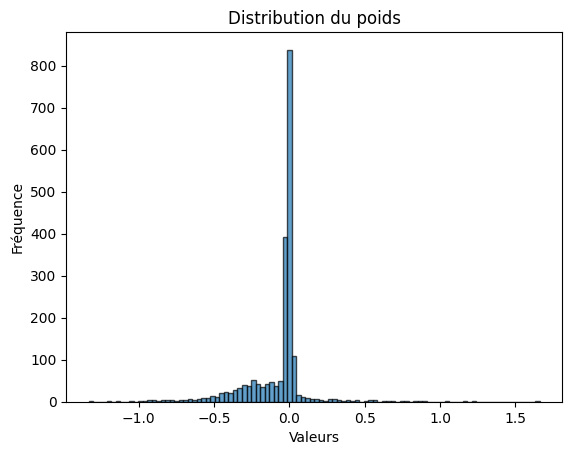

neurone 764 contribue avec une proportion 1.6610018014907837


100%|██████████| 194/194 [00:11<00:00, 16.31it/s]


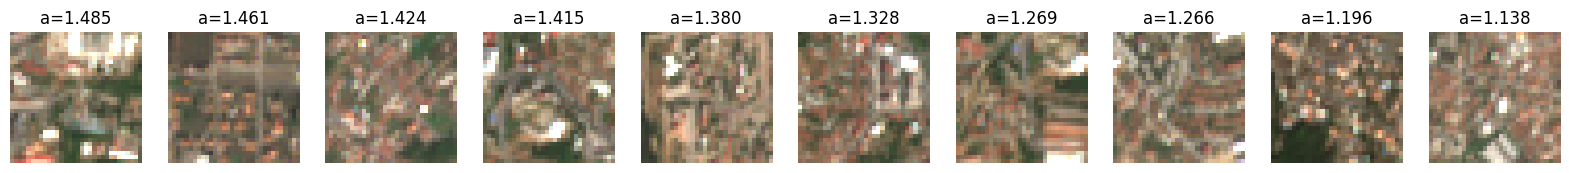

neurone 1579 contribue avec une proportion 1.2343239784240723


100%|██████████| 194/194 [00:11<00:00, 16.50it/s]


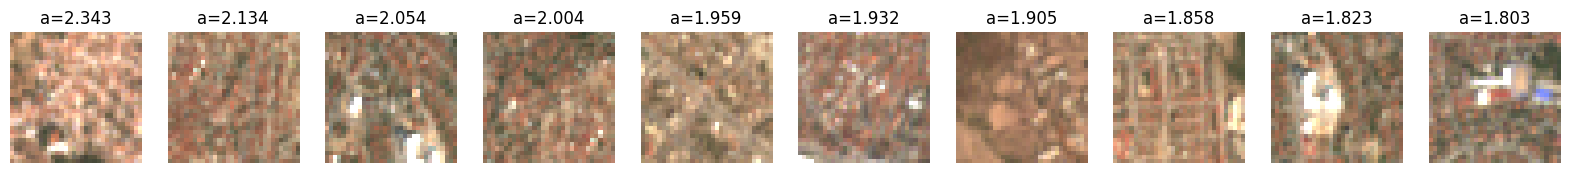

neurone 499 contribue avec une proportion 1.1671890020370483


100%|██████████| 194/194 [00:11<00:00, 16.39it/s]


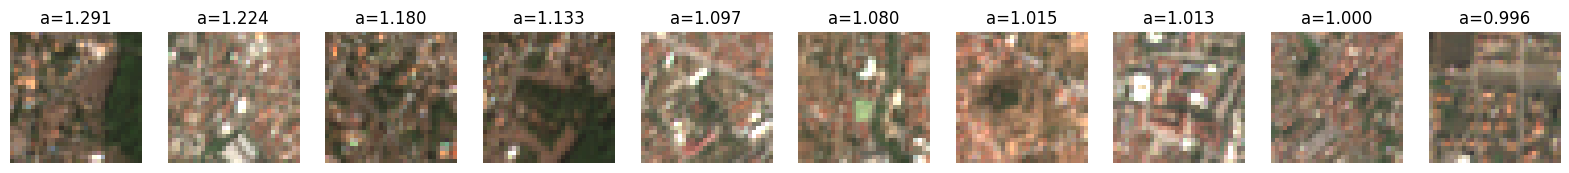

neurone 1425 contribue avec une proportion 1.0530688762664795


100%|██████████| 194/194 [00:11<00:00, 16.49it/s]


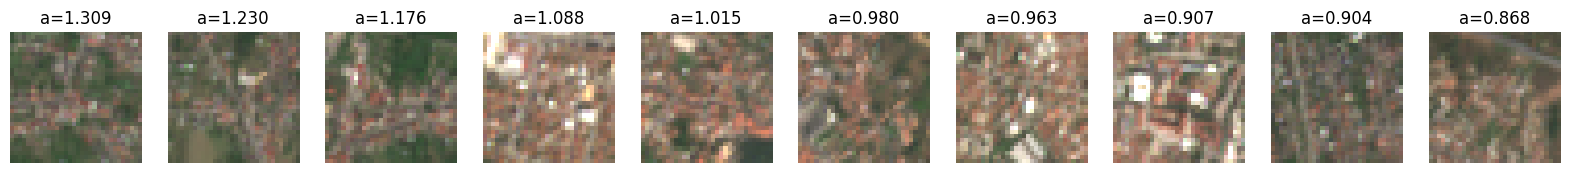

neurone 223 contribue avec une proportion -1.039524793624878


100%|██████████| 194/194 [00:11<00:00, 16.48it/s]


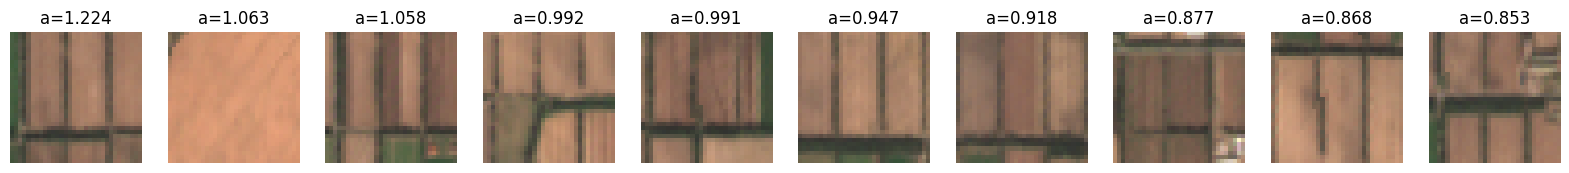

neurone 20 contribue avec une proportion -1.0501554012298584


100%|██████████| 194/194 [00:11<00:00, 16.39it/s]


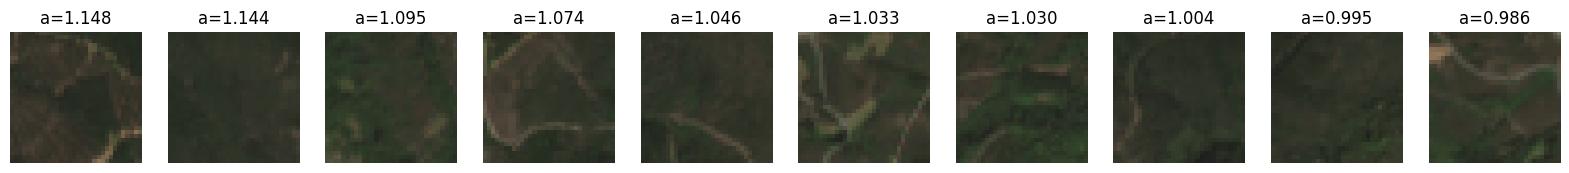

neurone 1141 contribue avec une proportion -1.1338746547698975


100%|██████████| 194/194 [00:11<00:00, 16.65it/s]


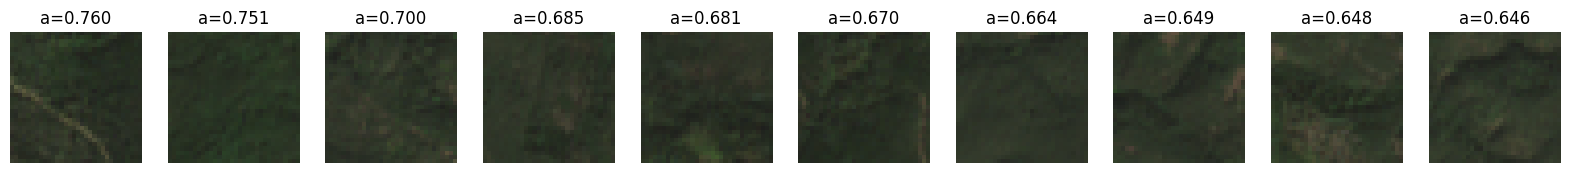

neurone 1219 contribue avec une proportion -1.1917082071304321


100%|██████████| 194/194 [00:11<00:00, 16.71it/s]


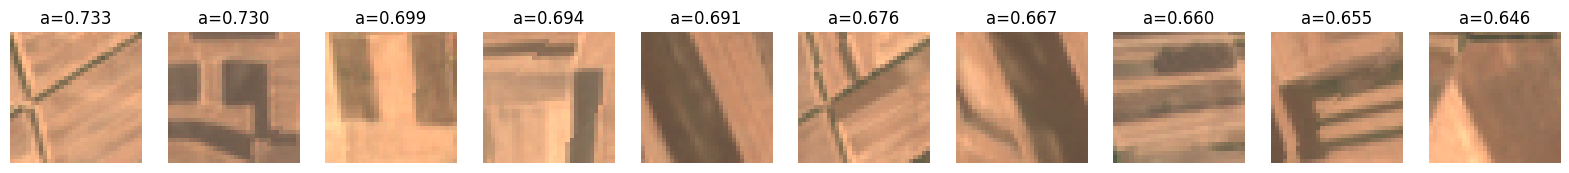

neurone 927 contribue avec une proportion -1.1953856945037842


100%|██████████| 194/194 [00:11<00:00, 16.61it/s]


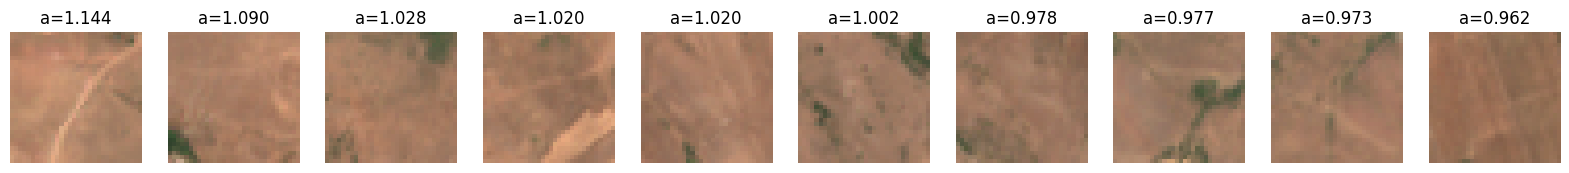

neurone 806 contribue avec une proportion -1.3309707641601562


100%|██████████| 194/194 [00:11<00:00, 16.69it/s]


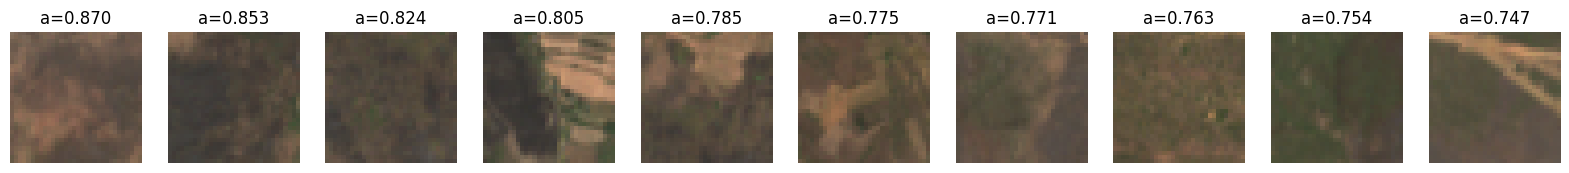

In [14]:
recherche_de_circuits(attribut_index=19, n_neurons=10)

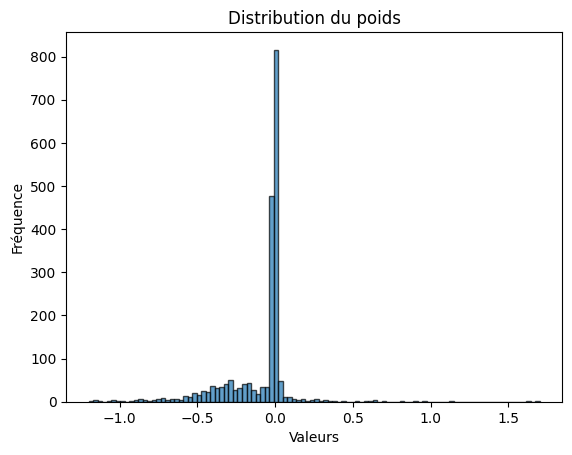

neurone 1695 contribue avec une proportion 1.7016124725341797


100%|██████████| 194/194 [00:11<00:00, 16.49it/s]


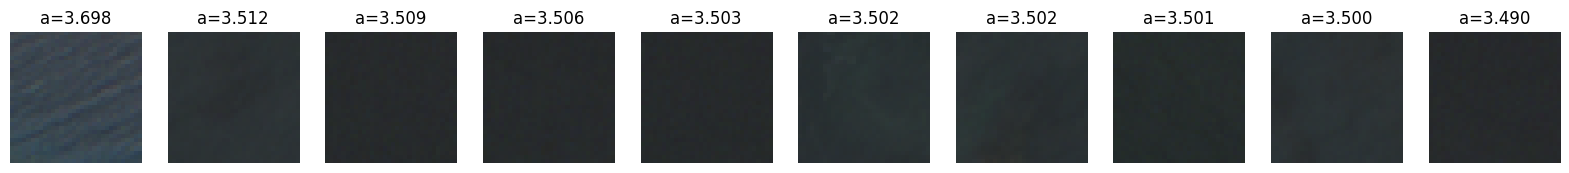

neurone 1416 contribue avec une proportion 1.6397221088409424


100%|██████████| 194/194 [00:11<00:00, 16.81it/s]


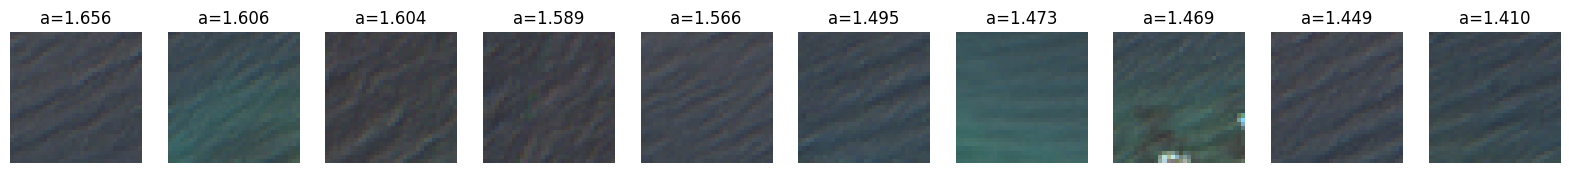

neurone 1097 contribue avec une proportion 1.1480356454849243


100%|██████████| 194/194 [00:10<00:00, 17.93it/s]


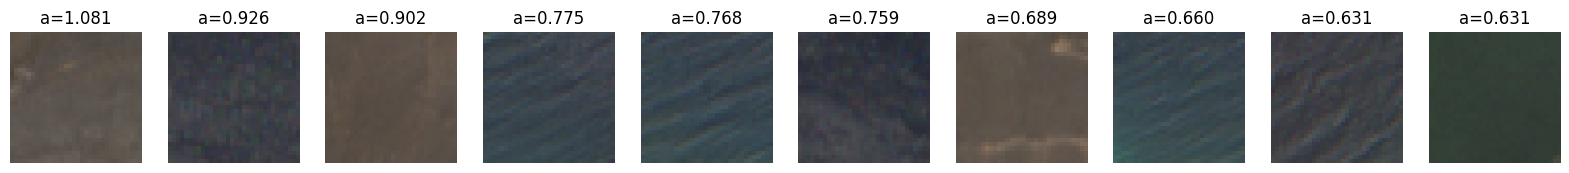

neurone 660 contribue avec une proportion -1.1293725967407227


100%|██████████| 194/194 [00:11<00:00, 16.69it/s]


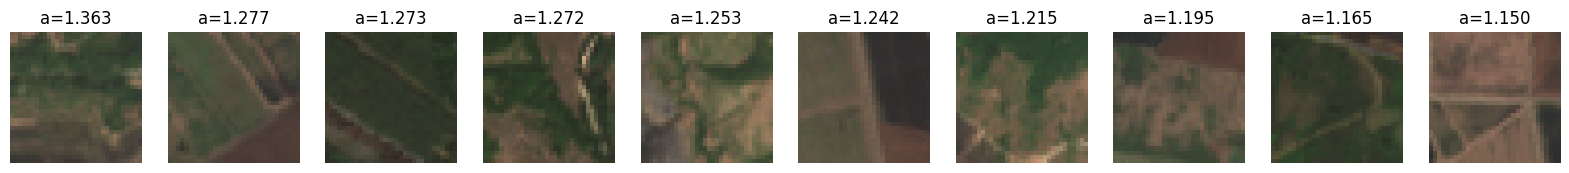

neurone 806 contribue avec une proportion -1.1297633647918701


100%|██████████| 194/194 [00:11<00:00, 16.52it/s]


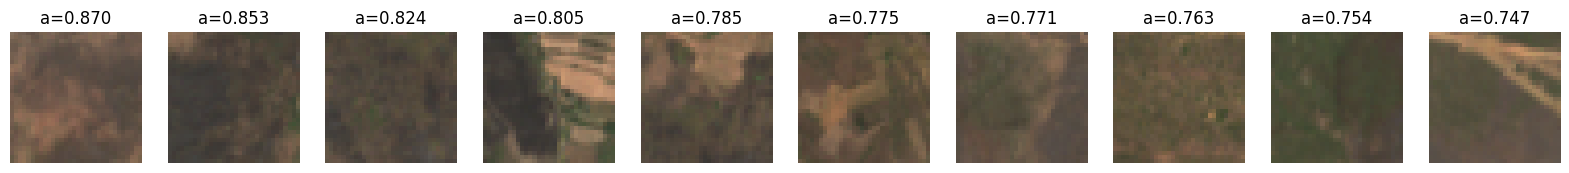

neurone 856 contribue avec une proportion -1.153764247894287


100%|██████████| 194/194 [00:13<00:00, 14.11it/s]


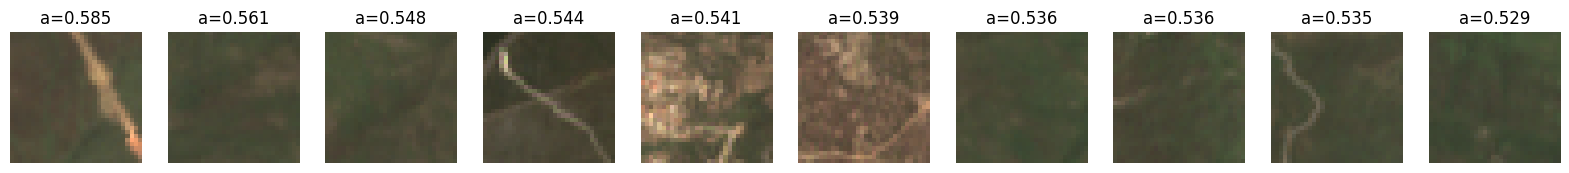

neurone 1178 contribue avec une proportion -1.1583184003829956


100%|██████████| 194/194 [00:11<00:00, 16.53it/s]


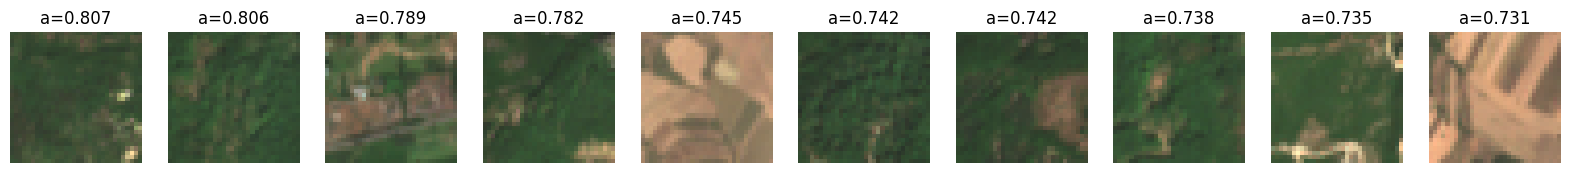

neurone 20 contribue avec une proportion -1.1584552526474


100%|██████████| 194/194 [00:11<00:00, 16.71it/s]


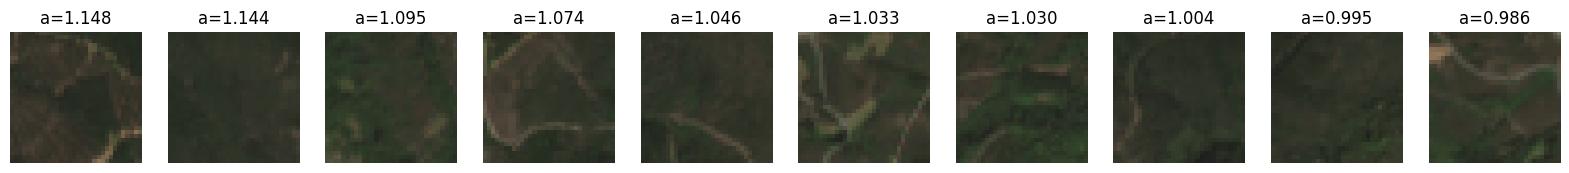

neurone 646 contribue avec une proportion -1.1916099786758423


100%|██████████| 194/194 [00:11<00:00, 16.65it/s]


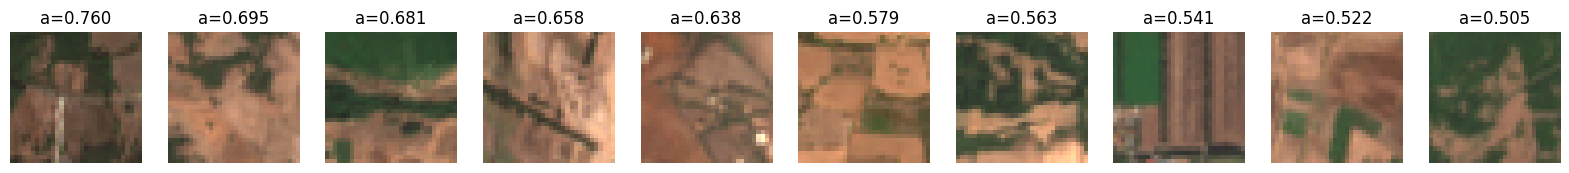

neurone 1522 contribue avec une proportion -1.1998950242996216


100%|██████████| 194/194 [00:11<00:00, 16.61it/s]


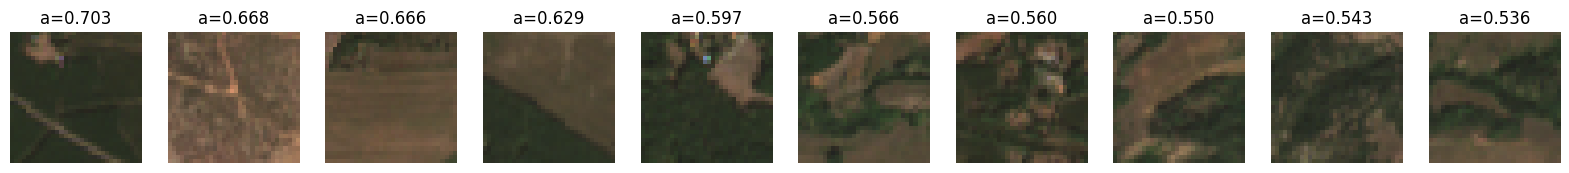

In [15]:
recherche_de_circuits(attribut_index=7, n_neurons=10)

In [17]:
indices_to_attributs = {
    0: "Trees entre 0 et 25 %",
    1: "Trees entre 25 et 50 %",
    2: "Trees entre 50 et 75 %",
    3: "Trees entre 75 et 100 %",

    4: "Water entre 0 et 25 %",
    5: "Water entre 25 et 50 %",
    6: "Water entre 50 et 75 %",
    7: "Water entre 75 et 100 %",

    8: "Flooded Vegetation entre 0 et 25 %",
    9: "Flooded Vegetation entre 25 et 50 %",
    10: "Flooded Vegetation entre 50 et 75 %",
    11: "Flooded Vegetation entre 75 et 100 %",

    12: "Grass entre 0 et 25 %",
    13: "Grass entre 25 et 50 %",
    14: "Grass entre 50 et 75 %",
    15: "Grass entre 75 et 100 %",

    16: "Built Area entre 0 et 25 %",
    17: "Built Area entre 25 et 50 %",
    18: "Built Area entre 50 et 75 %",
    19: "Built Area entre 75 et 100 %",

    20: "Scrub/shrub entre 0 et 25 %",
    21: "Scrub/shrub entre 25 et 50 %",
    22: "Scrub/shrub entre 50 et 75 %",
    23: "Scrub/shrub entre 75 et 100 %",

    24: "Crops entre 0 et 25 %",
    25: "Crops entre 25 et 50 %",
    26: "Crops entre 50 et 75 %",
    27: "Crops entre 75 et 100 %",

    28: "Trees damage 1 entre 0 et 25 %",
    29: "Trees damage 1 entre 25 et 50 %",
    30: "Trees damage 1 entre 50 et 75 %",
    31: "Trees damage 1 entre 75 et 100 %",

    32: "Trees damage 2 entre 0 et 25 %",
    33: "Trees damage 2 entre 25 et 50 %",
    34: "Trees damage 2 entre 50 et 75 %",
    35: "Trees damage 2 entre 75 et 100 %",

    36: "Trees damage 3 entre 0 et 25 %",
    37: "Trees damage 3 entre 25 et 50 %",
    38: "Trees damage 3 entre 50 et 75 %",
    39: "Trees damage 3 entre 75 et 100 %",

    40: "Trees damage 4 entre 0 et 25 %",
    41: "Trees damage 4 entre 25 et 50 %",
    42: "Trees damage 4 entre 50 et 75 %",
    43: "Trees damage 4 entre 75 et 100 %",

    44: "Scrub/shrub damage 1 entre 0 et 25 %",
    45: "Scrub/shrub damage 1 entre 25 et 50 %",
    46: "Scrub/shrub damage 1 entre 50 et 75 %",
    47: "Scrub/shrub damage 1 entre 75 et 100 %",

    48: "Scrub/shrub damage 2 entre 0 et 25 %",
    49: "Scrub/shrub damage 2 entre 25 et 50 %",
    50: "Scrub/shrub damage 2 entre 50 et 75 %",
    51: "Scrub/shrub damage 2 entre 75 et 100 %",

    52: "Scrub/shrub damage 3 entre 0 et 25 %",
    53: "Scrub/shrub damage 3 entre 25 et 50 %",
    54: "Scrub/shrub damage 3 entre 50 et 75 %",
    55: "Scrub/shrub damage 3 entre 75 et 100 %",

    56: "Scrub/shrub damage 4 entre 0 et 25 %",
    57: "Scrub/shrub damage 4 entre 25 et 50 %",
    58: "Scrub/shrub damage 4 entre 50 et 75 %",
    59: "Scrub/shrub damage 4 entre 75 et 100 %",
}

In [18]:
# CODE POUR DÉTERMINER LES CONTRIBUTIONS D'UN NEURONE AUX DIFFÉRENTS ATTRIBUTS

def contributions_neurone(neuron_idx, k=60):
    contributions = fully_connected[0].weight[:, neuron_idx]   # fully_connected[0].weight est de shape (60, 2048)
    
    values, indices = torch.topk(contributions.abs(), k)

    sorted_indices = indices[contributions[indices].argsort(descending=True)]    #  Trier ces indices par ordre décroissant de w[idx] (valeurs signées)

    for idx in sorted_indices:
        idx = idx.item()
        feature_name = indices_to_attributs[idx]
        contribution_value = contributions[idx].item()
        print(f"{'Feature '+str(idx):<10} | {feature_name:<40} | {contribution_value:>10.4f}")


In [19]:
# CODE POUR DÉTERMINER LES NEURONES QUI CONTRIBUENT FORTEMENT AUX DIFFÉRENTES ATTRIBUTS

def k_neurones_qui_contribuent_le_plus(k=10):
    W = fully_connected[0].weight
    mask = W > 0   # pour ne garder que les contributions positives
    W = W * mask
    neurones_contributions = W.sum(dim=0)
    valeurs, indices = torch.topk(neurones_contributions, k)
    return indices

indices = k_neurones_qui_contribuent_le_plus()
print(indices)

tensor([2013, 1414,  112,  499,  764, 1298, 1572,   22, 2000,  392],
       device='cuda:0')


Feature 19 | Built Area entre 75 et 100 %             |     1.6610
Feature 18 | Built Area entre 50 et 75 %              |     1.0932
Feature 17 | Built Area entre 25 et 50 %              |     0.7578
Feature 25 | Crops entre 25 et 50 %                   |     0.3875
Feature 24 | Crops entre 0 et 25 %                    |     0.3692
Feature 26 | Crops entre 50 et 75 %                   |     0.3108
Feature 12 | Grass entre 0 et 25 %                    |     0.3040
Feature 0  | Trees entre 0 et 25 %                    |     0.2924
Feature 1  | Trees entre 25 et 50 %                   |     0.2687
Feature 4  | Water entre 0 et 25 %                    |     0.1906
Feature 20 | Scrub/shrub entre 0 et 25 %              |     0.1553
Feature 32 | Trees damage 2 entre 0 et 25 %           |    -0.0946
Feature 36 | Trees damage 3 entre 0 et 25 %           |    -0.1201
Feature 27 | Crops entre 75 et 100 %                  |    -0.1202
Feature 2  | Trees entre 50 et 75 %                   |    -0.

100%|██████████| 194/194 [00:15<00:00, 12.58it/s]


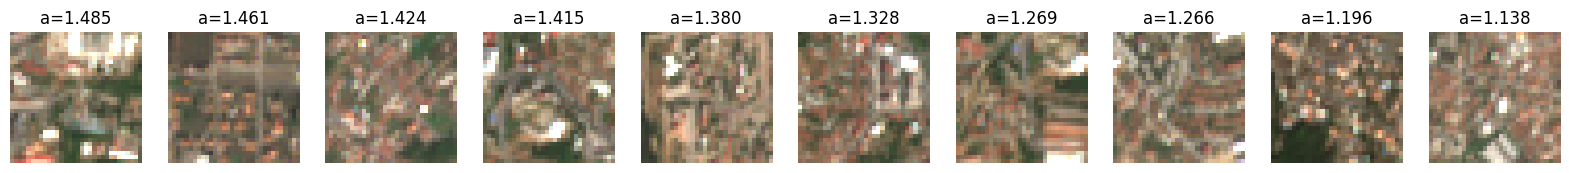

In [25]:
neuron_idx = 764
contributions_neurone(neuron_idx)
images_trigger_neurone(neuron_idx)